### Import functions

In [1]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score, homogeneity_score, completeness_score

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def make_plot(df, metrics, method_order, x_label):
    sns.set_theme(style="white")
    # metrics = [
    #     "NMI",
    #     "HOM",
    #     "COM"
    # ]
    
    # method_order = ['PCA', 'PCA+ASGC', 'PCA+ASGC+refinement']
    
    # Panel labels 
    panel_labels = ["a", "b", "c", "d", "e", "f"]
    panel_labels = panel_labels[:len(metrics)]
    
    # ============================================================
    # Figure (1 row, 3 columns)
    # ============================================================
    
    fig, axes = plt.subplots(
        1,
        len(metrics),
        figsize=(7.5, 3.2),  # Adjusted for a wide 1-row layout
        sharey=True
    )
    
    for i, (ax, metric, panel) in enumerate(zip(
        axes,
        metrics,
        panel_labels
    )):
    
        # --------------------------------------------------------
        # Boxplot
        # --------------------------------------------------------
    
        sns.boxplot(
            data=df,
            x=x_label,
            y=metric,
            order=method_order,
    
            width=0.55,
            linewidth=1.0,
            fliersize=0,
    
            boxprops={
                "facecolor": "white",
                "edgecolor": "black",
                "linewidth": 1.0
            },
    
            whiskerprops={
                "color": "black",
                "linewidth": 1.0
            },
    
            capprops={
                "color": "black",
                "linewidth": 1.0
            },
    
            medianprops={
                "color": "black",
                "linewidth": 1.5
            },
    
            ax=ax
        )
    
        sns.stripplot(
            data=df,
            x=x_label,
            y=metric,
            order=method_order,
    
            color="black",
            size=3.0,
            alpha=0.60,
    
            jitter=0.12,
    
            ax=ax
        )
    
        ax.text(
            -0.12,
            1.08,
            f"({panel})",
            transform=ax.transAxes,
    
            fontsize=10,
            fontweight="bold",
    
            va="top",
            ha="left"
        )
    
        ax.set_title(
            metric.replace("_", " ").title(),
            fontsize=9,
            fontweight="bold",
            pad=8
        )
    
        y_min = 0.4
        ax.set_ylim(y_min, 1.01)
    
        ax.set_yticks(
            np.arange(y_min, 1.01, 0.05)
        )
    
        ax.tick_params(
            axis="x",
            labelsize=7,
            rotation=35,
            direction="out",
            length=3,
            width=0.8
        )
    
        # Better alignment after rotation
        plt.setp(
            ax.get_xticklabels(),
            ha="right"
        )
    
        ax.tick_params(
            axis="y",
            labelsize=8,
            direction="out",
            length=3,
            width=0.8
        )
    
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
    
        ax.spines["left"].set_linewidth(0.8)
        ax.spines["bottom"].set_linewidth(0.8)
    
    
        # --------------------------------------------------------
        # Grid
        # --------------------------------------------------------
    
        ax.grid(
            axis="y",
            linestyle="--",
            linewidth=0.4,
            alpha=0.25
        )
    
        ax.set_axisbelow(True)
    
    plt.subplots_adjust(
        left=0.08,
        right=0.98,
        bottom=0.28,  # Increased bottom margin to fit rotated x-ticks
        top=0.88,
        wspace=0.25   # Spacing between columns
    )
    
    plt.show()

### Ablation study

In [16]:
dataname_list = [ '151507', '151508', '151509', '151510', '151669', '151670', '151671', '151672', '151673', '151674', '151675', '151676']
result_list = []
for test_id in dataname_list:
    ## PCAonly
    df = pd.read_csv('/data/hoan/spatial_transcriptomics/GraphBG-analysis/output/ablation/GraphBG_PCAonly_'+test_id+'.csv')
    predictions = df['cluster']
    celltypes_labels = df['ground_truth']
    
    # ari = adjusted_rand_score(celltypes_labels, predictions)
    NMI = normalized_mutual_info_score(celltypes_labels, predictions)
    HOM = homogeneity_score(celltypes_labels, predictions)
    COM = completeness_score(celltypes_labels, predictions)
    result_list.append([test_id, 'PCA', NMI, HOM, COM])

    ## PCA + ASGC
    df = pd.read_csv('/data/hoan/spatial_transcriptomics/GraphBG-analysis/output/ablation/GraphBG_PCAandASGC_'+test_id+'.csv')
    predictions = df['cluster']
    celltypes_labels = df['ground_truth']
    
    # ari = adjusted_rand_score(celltypes_labels, predictions)
    NMI = normalized_mutual_info_score(celltypes_labels, predictions)
    HOM = homogeneity_score(celltypes_labels, predictions)
    COM = completeness_score(celltypes_labels, predictions)
    result_list.append([test_id, 'PCA + ChebSpec', NMI, HOM, COM])

    ## GrapBG full
    df = pd.read_csv('/data/hoan/spatial_transcriptomics/GraphBG-analysis/output/ablation/GraphBG_full_'+test_id+'.csv')
    predictions = df['cluster']
    celltypes_labels = df['ground_truth']
    
    # ari = adjusted_rand_score(celltypes_labels, predictions)
    NMI = normalized_mutual_info_score(celltypes_labels, predictions)
    HOM = homogeneity_score(celltypes_labels, predictions)
    COM = completeness_score(celltypes_labels, predictions)
    result_list.append([test_id, 'PCA + ChebSpec + refinement', NMI, HOM, COM])

In [17]:
df2 = pd.DataFrame(result_list, columns = ['Dataset', 'Model', 'NMI', 'HOM', 'COM'])

In [19]:
df2[df2['Model']=='PCA + ChebSpec + refinement']

,Dataset,Model,NMI,HOM,COM
2,151507,PCA + ChebSpec + refinement,0.690970,0.669946,0.713357
5,151508,PCA + ChebSpec + refinement,0.637682,0.637457,0.637907
8,151509,PCA + ChebSpec + refinement,0.691697,0.670628,0.714134
11,151510,PCA + ChebSpec + refinement,0.650876,0.661153,0.640913
14,151669,PCA + ChebSpec + refinement,0.675974,0.621979,0.740235
17,151670,PCA + ChebSpec + refinement,0.616474,0.657569,0.580214
20,151671,PCA + ChebSpec + refinement,0.800710,0.777373,0.825492
23,151672,PCA + ChebSpec + refinement,0.720752,0.719932,0.721575
26,151673,PCA + ChebSpec + refinement,0.740522,0.723808,0.758026
29,151674,PCA + ChebSpec + refinement,0.740043,0.724169,0.756627


In [13]:
df2.groupby("Model")["COM"].mean()

Model
PCA                        0.482487
PCA+ChebSpec               0.639153
PCA+ChebSpec+refinement    0.710501
Name: COM, dtype: float64

In [ ]:
# df2.to_csv('output/ablation_GraphBG.csv', index=False)

In [39]:
df = df2.copy()

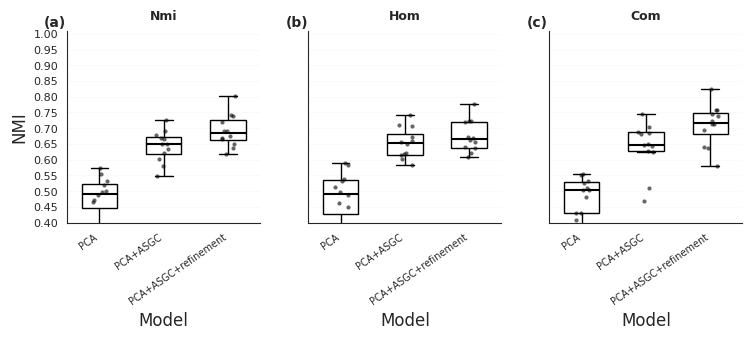

In [40]:
metrics = ['NMI', 'HOM','COM']
x_label = 'Model'
method_order = ['PCA', 'PCA+ASGC', 'PCA+ASGC+refinement']
make_plot(df2, metrics, method_order, x_label)

### Sensitivity: number of HVGs

In [53]:
result_list = []
for data_name in dataname_list:
    for n_hvg in [500, 1000, 2000, 3000, 5000]:
        df = pd.read_csv('/data/hoan/spatial_transcriptomics/GraphBG-analysis/output/ablation/GraphBG_HVG_' +str(n_hvg)+'_'+data_name+'.csv')
        predictions = df['cluster']
        celltypes_labels = df['ground_truth']
        
        # ari = adjusted_rand_score(celltypes_labels, predictions)
        NMI = normalized_mutual_info_score(celltypes_labels, predictions)
        HOM = homogeneity_score(celltypes_labels, predictions)
        COM = completeness_score(celltypes_labels, predictions)
        result_list.append([data_name, n_hvg, NMI, HOM, COM])

In [54]:
df3 = pd.DataFrame(result_list, columns = ['Dataset', 'n_HVGs', 'NMI', 'HOM', 'COM'])

In [55]:
df3.head(2)

,Dataset,n_HVGs,NMI,HOM,COM
0,151507,500,0.493928,0.424361,0.590777
1,151507,1000,0.663859,0.622669,0.710884


In [59]:
df3.groupby("n_HVGs")["COM"].mean()

n_HVGs
500     0.599851
1000    0.657997
2000    0.700617
3000    0.710501
5000    0.700359
Name: COM, dtype: float64

In [57]:
# df3.to_csv('output/GraphBG_sensitivity_nHVGs.csv',index=False)

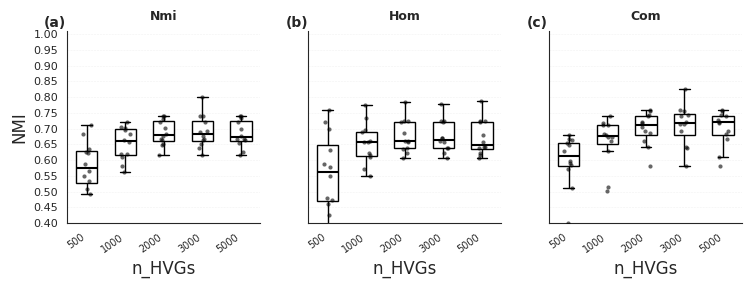

In [50]:
metrics = ['NMI', 'HOM','COM']
x_label = 'n_HVGs'
method_order = [500, 1000, 2000, 3000, 5000]
make_plot(df3, metrics, method_order, x_label)

### Sensitivity: number of PCs

In [60]:
result_list = []
for data_name in dataname_list:
    for n_pc in [10, 20, 30, 50, 80, 100]:
        df = pd.read_csv('/data/hoan/spatial_transcriptomics/GraphBG-analysis/output/ablation/GraphBG_nPCA_' +str(n_pc)+'_'+data_name+'.csv')
        predictions = df['cluster']
        celltypes_labels = df['ground_truth']
        
        # ari = adjusted_rand_score(celltypes_labels, predictions)
        NMI = normalized_mutual_info_score(celltypes_labels, predictions)
        HOM = homogeneity_score(celltypes_labels, predictions)
        COM = completeness_score(celltypes_labels, predictions)
        result_list.append([data_name, n_pc, NMI, HOM, COM])

In [61]:
df4 = pd.DataFrame(result_list, columns = ['Dataset', 'n_PCs', 'NMI', 'HOM', 'COM'])

In [62]:
df4.head(2)

,Dataset,n_PCs,NMI,HOM,COM
0,151507,10,0.626012,0.542894,0.739183
1,151507,20,0.690970,0.669946,0.713357


In [63]:
df4.groupby("n_PCs")["NMI"].mean()

n_PCs
10     0.680153
20     0.691604
30     0.686880
50     0.679769
80     0.676313
100    0.683451
Name: NMI, dtype: float64

In [64]:
df4.groupby("n_PCs")["HOM"].mean()

n_PCs
10     0.664177
20     0.675815
30     0.670223
50     0.679708
80     0.676825
100    0.678233
Name: HOM, dtype: float64

In [65]:
df4.groupby("n_PCs")["COM"].mean()

n_PCs
10     0.702046
20     0.710501
30     0.708101
50     0.686248
80     0.683263
100    0.693415
Name: COM, dtype: float64

In [36]:
# df4.to_csv('output/GraphBG_sensitivity_nPCs.csv',index=False)

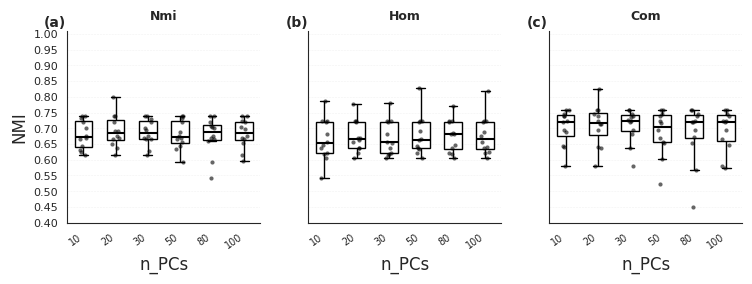

In [37]:
metrics = ['NMI', 'HOM','COM']
x_label = 'n_PCs'
method_order = [10, 20, 30, 50, 80, 100]
make_plot(df4, metrics, method_order, x_label)

### Sensitivity: number of neighbors

In [66]:
result_list = []
for data_name in dataname_list:
    for n_neighbors in [2, 4, 6, 8, 10]:
        df = pd.read_csv('/data/hoan/spatial_transcriptomics/GraphBG-analysis/output/ablation/GraphBG_nNeighbors_' +str(n_neighbors)+'_'+data_name+'.csv')
        predictions = df['cluster']
        celltypes_labels = df['ground_truth']
        
        # ari = adjusted_rand_score(celltypes_labels, predictions)
        NMI = normalized_mutual_info_score(celltypes_labels, predictions)
        HOM = homogeneity_score(celltypes_labels, predictions)
        COM = completeness_score(celltypes_labels, predictions)
        result_list.append([data_name, n_neighbors, NMI, HOM, COM])

In [67]:
df5 = pd.DataFrame(result_list, columns = ['Dataset', 'n_Neighbors', 'NMI', 'HOM', 'COM'])

In [68]:
df5.head(2)

,Dataset,n_Neighbors,NMI,HOM,COM
0,151507,2,0.666008,0.614819,0.726496
1,151507,4,0.690970,0.669946,0.713357


In [71]:
df5.groupby("n_Neighbors")["COM"].mean()

n_Neighbors
2     0.673585
4     0.710501
6     0.667851
8     0.650230
10    0.663558
Name: COM, dtype: float64

In [42]:
df5.to_csv('output/GraphBG_sensitivity_nNeighbors.csv',index=False)

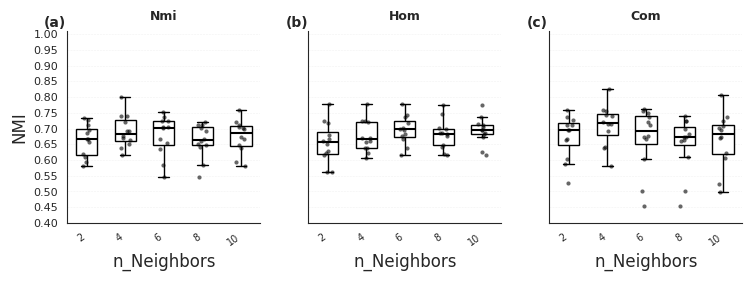

In [43]:
metrics = ['NMI', 'HOM','COM']
x_label = 'n_Neighbors'
method_order = [2, 4, 6, 8, 10]
make_plot(df5, metrics, method_order, x_label)